# SHL Grammar Scoring Engine: speaker-aware stack of frozen speech / audio-LLM / text encoders

**Task.** Predict a 0–5 grammar score for 45–60 s spoken-English clips (769 train, 216 test).
Leaderboard: RMSE (+ Pearson). **Final public score 0.3211** (rank ≈ 6 / 392), from a pipeline that
improved from 0.601 (hand features + LightGBM) step by step.

## Pipeline
```
wav ─┬─► WavLM-Large  (every layer, mean over time) ───────────────┐
     ├─► Whisper-large-v3 encoder (every layer) ───────────────────┤
     ├─► Voxtral-Mini-3B (audio LLM): hidden states + rubric digit ┤  Ridge / SVR per representation
     └─► Whisper (plain, and verbatim-prompted turbo) transcript ──┤  (speaker-grouped CV)
                 └─► DeBERTa-v3-large embeddings ─────────────────┘          │
                                                                   NNLS blend, fitted per recording batch
                                                                   → clip [2,5] → speaker pooling → zero gate
```
**Everything expensive is deterministic and cached** in three Kaggle datasets (embeddings, Voxtral
features, transcripts, crops, hand features); this notebook loads them and needs no GPU. It loads the
cached base-model predictions (≈ 1 minute); set `RECOMPUTE=1` to refit all 13 base models and the
nested CV from the cached features instead (a few minutes on CPU; same numbers, verified bit-identical
to the submitted predictions).

## The four ideas that mattered (all validated, see sections 2–5)
1. **Speaker-grouped validation.** Training speakers recorded ~3 answers each with near-identical grades;
   test speakers are unseen. Random K-fold leaks voice identity, so all CV is grouped by speaker.
2. **Zero gate.** The 37 clips graded 0 are a constantly loud noise batch: an energy rule catches all 37
   with no false positive; they are predicted 0 and excluded from regression training.
3. **Frozen encoders + simple heads.** With 769 clips, Ridge/SVR on mean-pooled hidden states of large
   pretrained models beat fine-tuning (our fine-tuned DeBERTa scored public 0.464, this stack 0.32).
4. **Test-length crops.** 47% of test clips are ~45 s against 14% of train, and less audio lowers every
   prediction. Models in the second regime also train on 4 test-length crops of each clip.

In [1]:
import glob
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from scipy.optimize import nnls
from scipy.sparse.csgraph import connected_components
from scipy.stats import pearsonr
from sklearn.base import clone
from sklearn.linear_model import Ridge
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
INPUT_ROOT = os.environ.get("INPUT_ROOT", "/kaggle/input")
OUT = os.environ.get("OUT_DIR", "/kaggle/working")
RECOMPUTE = os.environ.get("RECOMPUTE") == "1"  # refit all base models instead of loading base_preds.npz
N_JOBS = int(os.environ.get("N_JOBS", "4"))


def find(name, must=True):
    hits = glob.glob(f"{INPUT_ROOT}/**/{name}", recursive=True)
    assert hits or not must, f"{name} not found under {INPUT_ROOT}"
    return hits[0] if hits else None


def rmse(a, b):
    return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))


ROOT = os.path.dirname(find("train.csv"))
print("competition data:", ROOT, "| recompute:", RECOMPUTE)

competition data: /kaggle/input/competitions/shl-hiring-assessment-2026 | recompute: False


## 1. Data and exploration

train 769 / test 216 clips | label mean 3.31 std 1.24


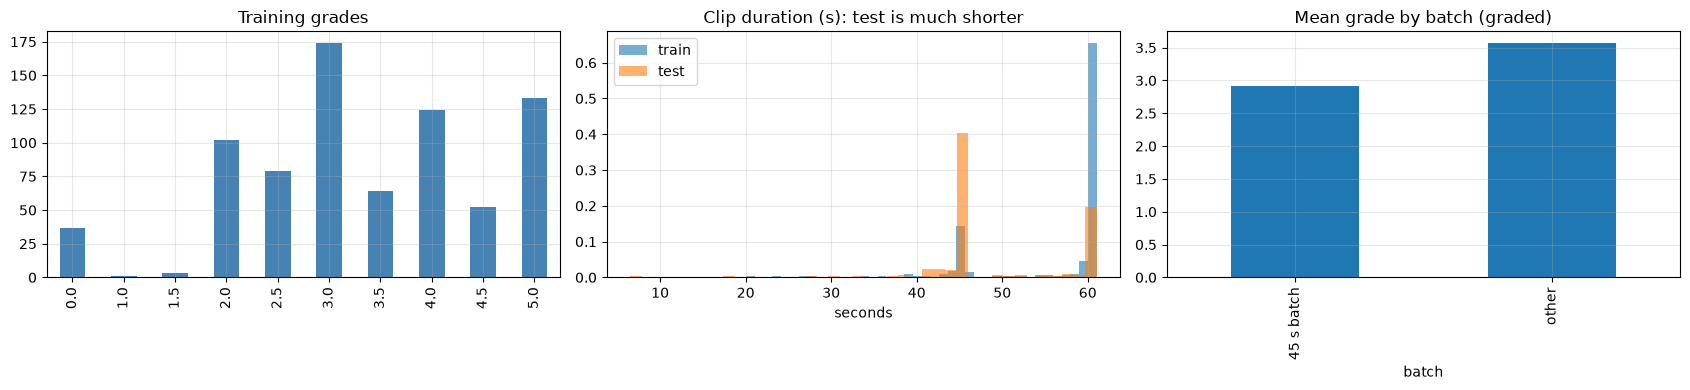

45 s batch: 14% of train, 47% of test


In [2]:
idx = pd.read_csv(find("emb_index.csv"))            # row order of every feature array: train rows then test rows
is_tr = (idx.split == "train").values
labels = pd.read_csv(f"{ROOT}/train.csv").set_index("filename")["label"]
y_all = labels.loc[idx.filename[is_tr]].values      # 769 grades


def hand(split):
    """text / LM-grammar / VAD-audio statistics from the first version of this project."""
    d = pd.concat([pd.read_csv(find(f"{g}_{split}.csv")).set_index("filename") for g in ("text", "lm", "audio")], axis=1)
    return d.loc[idx.filename[idx.split == split]]


H = pd.concat([hand("train"), hand("test")]).reset_index(drop=True)
duration = H.duration.values
energy = np.load(find("energy_ratio.npy"))
batch = np.where(np.abs(duration - 45.06) < 0.1, 0, 1)   # 0 = the ~45 s recording batch
print(f"train {is_tr.sum()} / test {(~is_tr).sum()} clips | label mean {y_all.mean():.2f} std {y_all.std():.2f}")

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
pd.Series(y_all).value_counts().sort_index().plot.bar(ax=ax[0], color="steelblue", title="Training grades")
ax[1].hist(duration[is_tr], 40, alpha=0.6, density=True, label="train")
ax[1].hist(duration[~is_tr], 40, alpha=0.6, density=True, label="test")
ax[1].set(title="Clip duration (s): test is much shorter", xlabel="seconds")
ax[1].legend()
b = pd.DataFrame({"batch": np.where(batch[is_tr] == 0, "45 s batch", "other"), "y": y_all})
b.loc[b.y > 0].groupby("batch").y.agg(["mean", "std", "count"]).round(2).plot.bar(y="mean", ax=ax[2], legend=False,
                                                                                    title="Mean grade by batch (graded)")
plt.tight_layout()
plt.show()
print(f"45 s batch: {(batch[is_tr] == 0).mean():.0%} of train, {(batch[~is_tr] == 0).mean():.0%} of test")

**Findings.** The ~45 s recording batch is 14% of train but **47% of test**, and its grades are lower
(2.9 vs 3.4). Test is therefore a different distribution from train: validation must respect that, and
the final blend is fitted separately per batch.

### 1a. The zero gate
The 37 clips graded 0 contain speech but are acoustically different: nearly every 25 ms frame is loud.

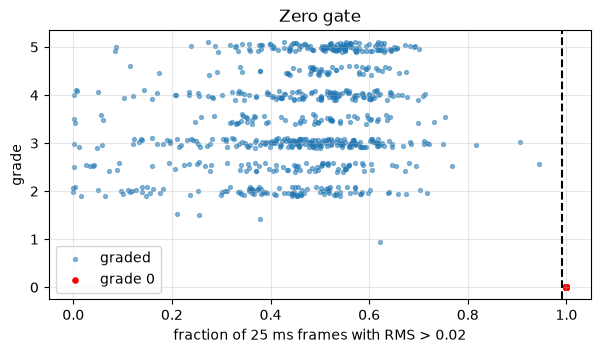

gate catches 37/37 zeros, false positives 0, flags 1 test clip(s)


In [3]:
zero = y_all == 0
gate = energy >= 0.99
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.scatter(energy[is_tr][~zero], y_all[~zero] + np.random.RandomState(0).uniform(-0.1, 0.1, (~zero).sum()), s=8, alpha=0.5, label="graded")
ax.scatter(energy[is_tr][zero], y_all[zero], s=14, c="r", label="grade 0")
ax.axvline(0.99, c="k", ls="--")
ax.set(xlabel="fraction of 25 ms frames with RMS > 0.02", ylabel="grade", title="Zero gate")
ax.legend()
plt.show()
print(f"gate catches {(gate[is_tr] & zero).sum()}/{zero.sum()} zeros, false positives {(gate[is_tr] & ~zero).sum()}, "
      f"flags {gate[~is_tr].sum()} test clip(s)")

## 2. Speaker groups
Early WavLM layers encode who is speaking. We link training clips whose voice similarity exceeds the
99.5th percentile of the **test→train** similarities (test speakers are unseen, so that distribution
describes *different* speakers); connected components are speaker groups.

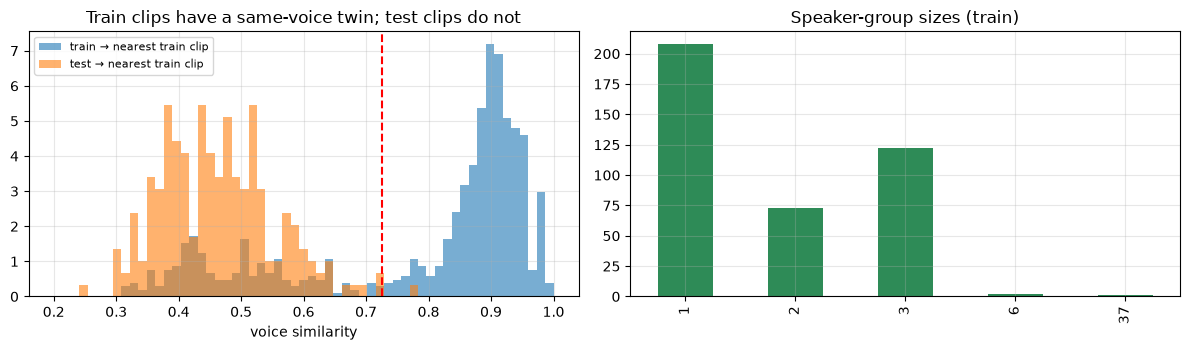

406 train speaker groups (sizes 1/2/3/4+: 208/73/122/3); grade std within a group 0.16 vs 1.01 overall


In [4]:
wavlm = np.load(find("emb_wavlm_mean.npy")).astype(np.float32)


def speaker_groups(emb, layers=(3, 6), pct=99.5):
    v = np.hstack([emb[:, l] for l in layers])
    v = (v - v.mean(0)) / (v.std(0) + 1e-6)
    v /= np.linalg.norm(v, axis=1, keepdims=True)
    sim = v @ v.T
    np.fill_diagonal(sim, -1)
    tr, te = np.where(is_tr)[0], np.where(~is_tr)[0]
    nn_te = sim[np.ix_(te, tr)].max(1)
    tau = np.percentile(nn_te, pct)
    g_tr = connected_components(sim[np.ix_(tr, tr)] > tau, directed=False)[1]
    g_te = connected_components(sim[np.ix_(te, te)] > tau, directed=False)[1]
    return g_tr, g_te, tau, sim[np.ix_(tr, tr)].max(1), nn_te


g_tr, g_te, tau, nn_tr, nn_te = speaker_groups(wavlm)
sizes = np.bincount(g_tr)
multi = [g for g in range(len(sizes)) if 1 < sizes[g] < 10 and (y_all[g_tr == g] > 0).all()]
within = np.mean([y_all[g_tr == g].std() for g in multi])
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
bins = np.linspace(0.2, 1, 60)
ax[0].hist(nn_tr, bins, alpha=0.6, density=True, label="train → nearest train clip")
ax[0].hist(nn_te, bins, alpha=0.6, density=True, label="test → nearest train clip")
ax[0].axvline(tau, c="r", ls="--")
ax[0].set(xlabel="voice similarity", title="Train clips have a same-voice twin; test clips do not")
ax[0].legend(fontsize=8)
pd.Series(sizes).value_counts().sort_index().plot.bar(ax=ax[1], title="Speaker-group sizes (train)", color="seagreen")
plt.tight_layout()
plt.show()
print(f"{len(sizes)} train speaker groups (sizes 1/2/3/4+: {(sizes == 1).sum()}/{(sizes == 2).sum()}/{(sizes == 3).sum()}/{(sizes >= 4).sum()}); "
      f"grade std within a group {within:.2f} vs {y_all[y_all > 0].std():.2f} overall")

Most speakers have 3 near-identical-grade answers (std within a group is a fraction of the overall std).
(The single group of size 37 is the 37 zero-graded clips: they share one noisy recording source, so they
look like one "voice"; they are handled by the gate and excluded from regression.)
A random split puts a speaker's other answers in the training fold, which rewards memorising voices —
so **all CV below is `StratifiedGroupKFold` over these groups** (5 folds × 3 repeats).

In [5]:
nz = ~zero                               # regression is trained / validated on graded clips only
y, groups = y_all[nz], g_tr[nz]
fbins = np.maximum(np.round(y * 2).astype(int), 4)
FOLDS = [list(StratifiedGroupKFold(5, shuffle=True, random_state=s).split(y, fbins, groups)) for s in range(3)]
b_tr, b_te = batch[is_tr][nz], batch[~is_tr]

## 3. Frozen representations
Each clip is described by **mean-pooled hidden states** of large pretrained models (stored for every
layer; a 3-layer window per model was chosen by a grouped-CV Ridge sweep):

| representation | model | layers used | single-model grouped-CV RMSE |
|---|---|---|---|
| speech | WavLM-Large | 19–21 | 0.585 |
| speech | Whisper-large-v3 encoder | 30–32 | 0.575 |
| audio LLM | Voxtral-Mini-3B hidden states (mean+std, 20–60 % depth) | pooled | **0.548** |
| text | DeBERTa-v3-large over the Whisper transcript | 21–23 | 0.607 |
| text (verbatim) | DeBERTa-v3-large over a verbatim-prompted Whisper-turbo transcript | 21–23 | 0.62 (crop-val) |

The **verbatim prompt** ("Umm, so I goes to the, uh, the market…") stops Whisper from silently correcting
grammar ("he don't" → "he doesn't"), which would erase the very errors being graded
(fillers per clip 1.3 → 5.0). Voxtral listens to the audio directly, so it also hears what a transcript hides.

In [6]:
def win(name, layers):
    return np.load(find(name)).astype(np.float32)[:, layers].mean(1)


Z = {  # full-clip representations over all 985 rows
    "wavlm": win("emb_wavlm_mean.npy", [19, 20, 21]),
    "whisper": win("emb_whisper_mean.npy", [30, 31, 32]),
    "text": win("emb_text_mean.npy", [21, 22, 23]),
    "text_vb": win("emb_text_verbatim_full_mean.npy", [21, 22, 23]),
    "voxtral": np.load(find("voxtral_full.npy")).astype(np.float32),
}
Zc = {  # test-length crops of the train clips (4 per clip; order = crops.csv)
    "wavlm": win("emb_wavlm_crops_mean.npy", [19, 20, 21]),
    "whisper": win("emb_whisper_crops_mean.npy", [30, 31, 32]),
    "text_vb": win("emb_text_verbatim_crops_mean.npy", [21, 22, 23]),
    "voxtral": np.load(find("voxtral_crops.npy")).astype(np.float32),
}
judge = pd.read_csv(find("voxtral_judge_full.csv")).values.astype(np.float32)   # Voxtral's own 1-5 rubric digit
Z["audio_vox"] = np.hstack([Z["wavlm"], Z["whisper"], Z["voxtral"]])
Zc["audio_vox"] = np.hstack([Zc["wavlm"], Zc["whisper"], Zc["voxtral"]])
Z["hand_judge"] = np.hstack([H.values.astype(np.float32), judge])

crops = pd.read_csv(find("crops.csv"))
row_of = pd.Series(np.arange(is_tr.sum()), index=idx.filename[is_tr].values).loc[crops.filename].values
keep = nz[row_of]                                                    # drop crops of zero-graded clips
parent = pd.Series(np.arange(nz.sum()), index=np.where(nz)[0]).loc[row_of[keep]].values
print({k: v.shape for k, v in Z.items()}, "| crops kept:", keep.sum())

{'wavlm': (985, 1024), 'whisper': (985, 1280), 'text': (985, 1024), 'text_vb': (985, 1024), 'voxtral': (985, 6144), 'audio_vox': (985, 8448), 'hand_judge': (985, 31)} | crops kept: 2928


## 4. Base models (two training regimes)
* **Regime A, full clips:** 6 models, trained and validated on whole clips.
* **Regime B, test-length crops:** 7 models trained on full clips + 4 crops per clip; a validation clip is
  scored by the **mean prediction over its crops** so CV measures test-like lengths.

Heads are `StandardScaler → Ridge(alpha = d)` or `RBF-SVR(C = 3, gamma = 1/d)` (d = feature count).
All base predictions are **out-of-fold**; the blend is therefore fitted on honest predictions only.

In [7]:
def ridge(d, alpha=1.0):
    return make_pipeline(StandardScaler(), Ridge(alpha=alpha * d))


def svr(d, C=3.0):
    return make_pipeline(StandardScaler(), SVR(C=C, gamma=1.0 / d, epsilon=0.1))


def spec(items):
    out = {}
    for name, rep, kind in items:
        d = Z[rep].shape[1]
        out[name] = (rep, ridge(d) if kind == "ridge" else svr(d) if kind == "svr" else make_pipeline(StandardScaler(), SVR(C=1)))
    return out


A = spec([("voxtral_ridge", "voxtral", "ridge"), ("voxtral_svr", "voxtral", "svr"), ("audio_vox_ridge", "audio_vox", "ridge"),
          ("hand_judge_svr", "hand_judge", "svr1"), ("whisper_svr", "whisper", "svr"), ("text_ridge", "text", "ridge")])
B = spec([("wavlm_ridge", "wavlm", "ridge"), ("whisper_ridge", "whisper", "ridge"), ("whisper_svr", "whisper", "svr"),
          ("voxtral_ridge", "voxtral", "ridge"), ("audio_vox_ridge", "audio_vox", "ridge"),
          ("text_vb_ridge", "text_vb", "ridge"), ("text_vb_svr", "text_vb", "svr")])


def fit_fold(model, Xf, Xc, tr, va, Xte, r):
    """Train on full rows (+ their crops in regime B); predict the validation clips and the test clips."""
    if Xc is None:
        m = clone(model).fit(Xf[tr], y[tr])
        pv = m.predict(Xf[va])
    else:
        in_tr = np.isin(parent, tr)
        m = clone(model).fit(np.vstack([Xf[tr], Xc[in_tr]]), np.concatenate([y[tr], y[parent[in_tr]]]))
        in_va = np.isin(parent, va)
        pv = pd.Series(m.predict(Xc[in_va])).groupby(parent[in_va]).mean().reindex(va).values
    return r, va, pv, m.predict(Xte)


def regime(models, use_crops):
    oofs, tes, ins = [], [], []
    for name, (rep, model) in models.items():
        Xf, Xte = Z[rep][is_tr][nz], Z[rep][~is_tr]
        Xc = Zc[rep][keep] if use_crops else None
        runs = Parallel(n_jobs=N_JOBS)(delayed(fit_fold)(model, Xf, Xc, tr, va, Xte, r)
                                       for r, fold in enumerate(FOLDS) for tr, va in fold)
        oof, te = np.zeros((len(FOLDS), len(y))), np.zeros(len(Xte))
        for r, va, pv, t in runs:
            oof[r, va] = pv
            te += t / len(runs)
        # in-sample (training-data) predictions: refit on every graded clip, predict those same clips
        Xall = np.vstack([Xf, Xc]) if use_crops else Xf
        yall = np.concatenate([y, y[parent]]) if use_crops else y
        ins.append(np.clip(clone(model).fit(Xall, yall).predict(Xf), 1, 5))
        oofs.append(np.clip(oof, 1, 5))
        tes.append(np.clip(te, 1, 5))
        print(f"  {name:16s} grouped-CV RMSE {np.mean([rmse(o, y) for o in oofs[-1]]):.4f}", flush=True)
    return np.stack(oofs, -1), np.stack(tes, -1), np.stack(ins, -1)

In [8]:
cache = find("base_preds.npz", must=False)
if cache and not RECOMPUTE:
    c = np.load(cache)
    P = {k: (c[f"{k}_oof"], c[f"{k}_te"], c[f"{k}_in"]) for k in ("A", "B")}
    # reuse the exact folds the cached OOF predictions were made with (fold splits can differ across sklearn versions)
    FOLDS = [[(np.where(fid != f)[0], np.where(fid == f)[0]) for f in range(5)] for fid in c["fold_id"]]
    print("loaded cached base-model predictions:", cache)
    for k, models in (("A", A), ("B", B)):
        for j, name in enumerate(models):
            print(f"  {k}/{name:16s} grouped-CV RMSE {np.mean([rmse(o, y) for o in P[k][0][..., j]]):.4f}")
else:
    print("Regime A (full clips)")
    PA = regime(A, False)
    print("Regime B (full clips + 4 test-length crops, validated on crops)")
    PB = regime(B, True)
    P = {"A": PA, "B": PB}
    fold_id = np.zeros((len(FOLDS), len(y)), int)
    for r, fold in enumerate(FOLDS):
        for f, (_, va) in enumerate(fold):
            fold_id[r, va] = f
    np.savez_compressed(f"{OUT}/base_preds.npz", fold_id=fold_id,
                        **{f"{k}_{t}": v for k, tup in P.items() for t, v in zip(("oof", "te", "in"), tup)})

loaded cached base-model predictions: /kaggle/input/datasets/sibikrish3000/shl-features/base_preds.npz
  A/voxtral_ridge    grouped-CV RMSE 0.5477
  A/voxtral_svr      grouped-CV RMSE 0.5743
  A/audio_vox_ridge  grouped-CV RMSE 0.5383
  A/hand_judge_svr   grouped-CV RMSE 0.7150
  A/whisper_svr      grouped-CV RMSE 0.5781
  A/text_ridge       grouped-CV RMSE 0.6002
  B/wavlm_ridge      grouped-CV RMSE 0.6014
  B/whisper_ridge    grouped-CV RMSE 0.6052
  B/whisper_svr      grouped-CV RMSE 0.5832
  B/voxtral_ridge    grouped-CV RMSE 0.5555
  B/audio_vox_ridge  grouped-CV RMSE 0.5498
  B/text_vb_ridge    grouped-CV RMSE 0.6229
  B/text_vb_svr      grouped-CV RMSE 0.6133


## 5. Blend: NNLS per recording batch, clip, speaker pooling, gate
* **Non-negative least squares with intercept** over the base models' OOF predictions, fitted
  **separately for the 45 s batch and the rest** (47 % of test vs 14 % of train: the transcript models
  get more weight on the 45 s batch, the audio models on 60 s clips).
* Predictions clipped to **[2, 5]** (grades below 2 are < 1 % of graded clips).
* **Speaker pooling:** shrink each test prediction toward the mean of its speaker group (test speakers
  also repeat); the strength α is chosen on CV.
* **Gate:** clips with energy ratio ≥ 0.99 are set to exactly 0.

In [9]:
def nnls_fit(Pm, t):
    pm, tm = Pm.mean(0), t.mean()
    w, _ = nnls(Pm - pm, t - tm)
    return w, tm - pm @ w


def blend(P_fit, t_fit, b_fit, P_new, b_new):
    out = np.zeros(len(P_new))
    for bb in (0, 1):
        w, c = nnls_fit(P_fit[b_fit == bb], t_fit[b_fit == bb])
        out[b_new == bb] = P_new[b_new == bb] @ w + c
    return out


def pool(pred, g, alpha):
    return (1 - alpha) * pred + alpha * pd.Series(pred).groupby(g).transform("mean").values


def final_regime(P_oof, P_te, P_in):
    """Nested blend CV, pooling strength, test prediction and in-sample prediction for one regime."""
    st = np.zeros((len(FOLDS), len(y)))
    for r, fold in enumerate(FOLDS):          # blend weights fitted on the other folds' OOF rows only
        for tr, va in fold:
            st[r, va] = blend(P_oof[r][tr], y[tr], b_tr[tr], P_oof[r][va], b_tr[va])
    st = np.clip(st, 2, 5)
    alphas = [0, 0.25, 0.5, 0.75, 1.0]
    cv = {a: float(np.mean([rmse(pool(s, groups, a), y) for s in st])) for a in alphas}
    alpha = min(cv, key=cv.get)
    Pm = P_oof.mean(0)
    test = np.clip(blend(Pm, y, b_tr, P_te, b_te), 2, 5)
    test = pool(test, g_te, alpha)
    ins = pool(np.clip(blend(Pm, y, b_tr, P_in, b_tr), 2, 5), groups, alpha)
    oof_final = pool(st.mean(0), groups, alpha)
    return dict(st=st, cv=cv, alpha=alpha, test=test, ins=ins, oof=oof_final, Pm=Pm)


R = {k: final_regime(*P[k]) for k in ("A", "B")}
for k, nm in (("A", "A: full-clip models"), ("B", "B: crop-trained models")):
    r = R[k]
    print(f"{nm}: nested blend CV {np.mean([rmse(s, y) for s in r['st']]):.4f} → pooled (α={r['alpha']}) {r['cv'][r['alpha']]:.4f}")

A: full-clip models: nested blend CV 0.5201 → pooled (α=0.5) 0.5130
B: crop-trained models: nested blend CV 0.5251 → pooled (α=0.5) 0.5163


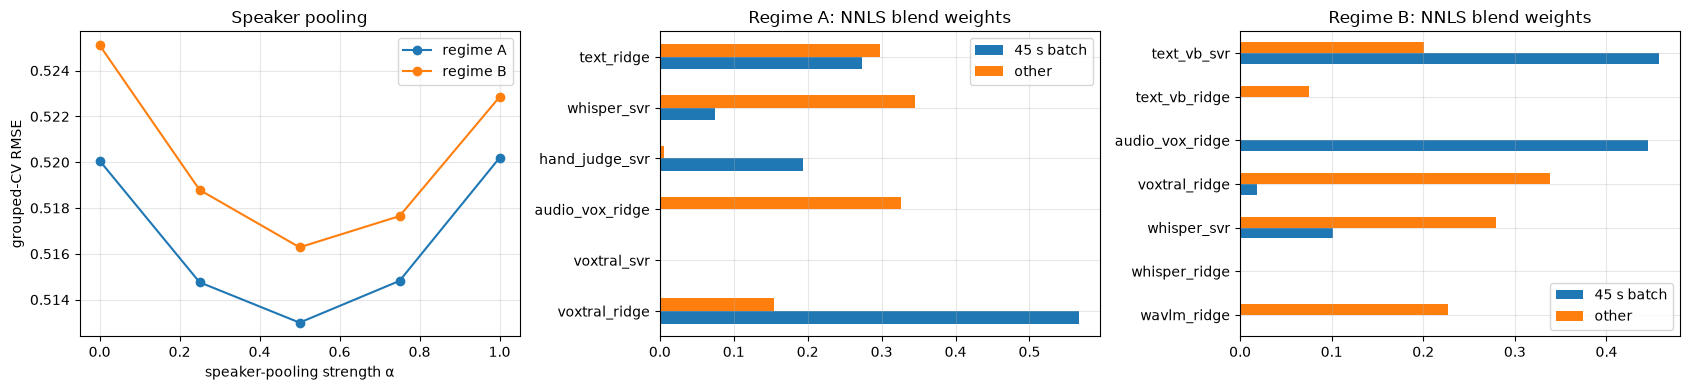

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
for k, c in (("A", "tab:blue"), ("B", "tab:orange")):
    ax[0].plot(list(R[k]["cv"]), list(R[k]["cv"].values()), "o-", c=c, label=f"regime {k}")
ax[0].set(xlabel="speaker-pooling strength α", ylabel="grouped-CV RMSE", title="Speaker pooling")
ax[0].legend()
for a_, (k, models) in zip(ax[1:], (("A", A), ("B", B))):
    w = pd.DataFrame({lab: nnls_fit(R[k]["Pm"][b_tr == bb], y[b_tr == bb])[0] for lab, bb in (("45 s batch", 0), ("other", 1))},
                     index=list(models))
    w.plot.barh(ax=a_, title=f"Regime {k}: NNLS blend weights")
plt.tight_layout()
plt.show()

## 6. Final prediction: mean of the two regimes
The two regimes make different mistakes (full-clip models vs crop-trained models with verbatim transcripts;
prediction correlation ≈ 0.987), so their plain average scored best on the public leaderboard.

In [11]:
gated = gate[~is_tr]
test_final = 0.5 * (R["A"]["test"] + R["B"]["test"])
test_final[gated] = 0.0
sub = pd.DataFrame({"filename": idx.filename[~is_tr].values, "label": test_final})
assert len(sub) == 216 and sub.label.between(0, 5).all()
sub.to_csv(f"{OUT}/submission.csv", index=False)

## 7. Evaluation
**Training-data RMSE (required).** Every base model is refit on *all* graded training clips (regime B
also on their crops), predictions are made on those same training clips, blended with the final weights,
clipped, pooled and gated. This in-sample figure is optimistic by construction; the **grouped-CV** RMSE
(out-of-fold, speaker-disjoint) is the honest estimate.

In [12]:
def full_train(ins_pred, k):
    p = np.zeros(len(y_all))
    p[nz] = ins_pred
    p[gate[is_tr]] = 0.0
    return p


tr_in = {k: full_train(R[k]["ins"], k) for k in ("A", "B")}
tr_in["A+B"] = 0.5 * (tr_in["A"] + tr_in["B"])
cv_oof = {k: full_train(R[k]["oof"], k) for k in ("A", "B")}
cv_oof["A+B"] = 0.5 * (cv_oof["A"] + cv_oof["B"])
res = pd.DataFrame({
    "training RMSE (in-sample)": {k: rmse(y_all, v) for k, v in tr_in.items()},
    "grouped-CV RMSE (all train clips, honest)": {k: rmse(y_all, v) for k, v in cv_oof.items()},
    "grouped-CV Pearson": {k: pearsonr(y_all, v)[0] for k, v in cv_oof.items()},
}).round(4)
res.index = ["A: full-clip models", "B: crop-trained models", "A+B (final)"]
res.loc["baseline: predict the mean"] = [rmse(y_all, np.full_like(y_all, y_all.mean())), rmse(y_all, np.full_like(y_all, y_all.mean())), np.nan]
print(f"TRAINING RMSE (final A+B, in-sample): {rmse(y_all, tr_in['A+B']):.4f}")
print(f"GROUPED-CV RMSE (final A+B, out-of-fold): {rmse(y_all, cv_oof['A+B']):.4f}   Pearson {pearsonr(y_all, cv_oof['A+B'])[0]:.4f}")
res

TRAINING RMSE (final A+B, in-sample): 0.2366
GROUPED-CV RMSE (final A+B, out-of-fold): 0.4947   Pearson 0.9170


,training RMSE (in-sample),"grouped-CV RMSE (all train clips, honest)",grouped-CV Pearson
A: full-clip models,0.283900,0.497100,0.9161
B: crop-trained models,0.203800,0.499600,0.9153
A+B (final),0.236600,0.494700,0.9170
baseline: predict the mean,1.238194,1.238194,NaN


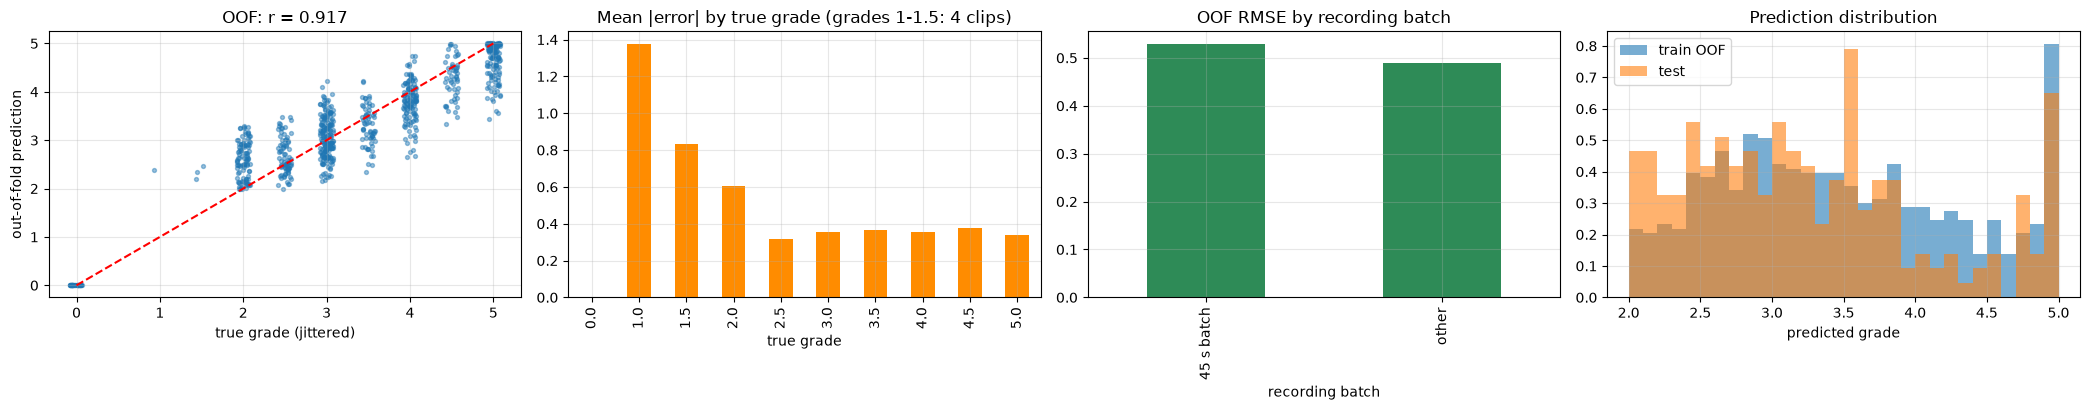

In [13]:
oofp = cv_oof["A+B"]
fig, ax = plt.subplots(1, 4, figsize=(21, 4.2))
ax[0].scatter(y_all + np.random.RandomState(1).uniform(-0.08, 0.08, len(y_all)), oofp, s=8, alpha=0.45)
ax[0].plot([0, 5], [0, 5], "r--")
ax[0].set(xlabel="true grade (jittered)", ylabel="out-of-fold prediction", title=f"OOF: r = {pearsonr(y_all, oofp)[0]:.3f}")
err = pd.DataFrame({"y": y_all, "e": np.abs(oofp - y_all)}).groupby("y").e.mean()
err.index.name = "true grade"
err.plot.bar(ax=ax[1], color="darkorange", title="Mean |error| by true grade (grades 1-1.5: 4 clips)")
bt = pd.DataFrame({"b": np.where(batch[is_tr] == 0, "45 s batch", "other"), "se": (oofp - y_all) ** 2}).groupby("b").se.mean() ** 0.5
bt.index.name = "recording batch"
bt.plot.bar(ax=ax[2], color="seagreen", title="OOF RMSE by recording batch")
ax[3].hist(oofp[nz], 30, alpha=0.6, density=True, label="train OOF")
ax[3].hist(test_final[~gated], 30, alpha=0.6, density=True, label="test")
ax[3].set(title="Prediction distribution", xlabel="predicted grade")
ax[3].legend()
plt.tight_layout()
plt.show()

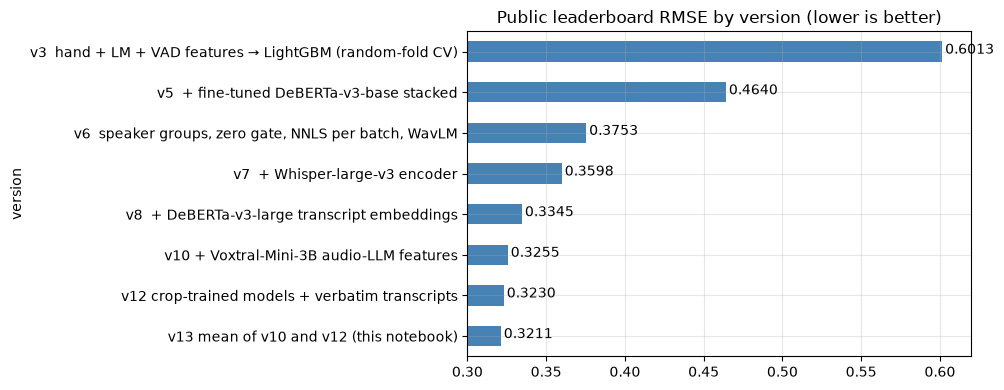

In [14]:
prog = pd.DataFrame([
    ("v3  hand + LM + VAD features → LightGBM (random-fold CV)", 0.6013),
    ("v5  + fine-tuned DeBERTa-v3-base stacked", 0.4640),
    ("v6  speaker groups, zero gate, NNLS per batch, WavLM", 0.3753),
    ("v7  + Whisper-large-v3 encoder", 0.3598),
    ("v8  + DeBERTa-v3-large transcript embeddings", 0.3345),
    ("v10 + Voxtral-Mini-3B audio-LLM features", 0.3255),
    ("v12 crop-trained models + verbatim transcripts", 0.3230),
    ("v13 mean of v10 and v12 (this notebook)", 0.3211),
], columns=["version", "public RMSE"])
ax = prog.set_index("version")["public RMSE"][::-1].plot.barh(figsize=(10, 4), color="steelblue", xlim=(0.3, 0.62),
                                                              title="Public leaderboard RMSE by version (lower is better)")
for p, v in zip(ax.patches, prog["public RMSE"][::-1]):
    ax.text(v + 0.002, p.get_y() + 0.2, f"{v:.4f}")
plt.tight_layout()
plt.show()

## 8. Report
**Preprocessing.** Audio is read as mono 16 kHz. Transcripts: Whisper-large-v3 (plain) and
Whisper-large-v3-turbo with a verbatim-style prompt, full clips and 4 test-length crops per train clip.
No external data and no test labels are used. Test-time speaker pooling uses only test audio (voice
similarity), never labels.

**Architecture.** Frozen encoders → per-representation Ridge/SVR heads → NNLS blend per recording
batch → clip → speaker pooling → zero gate; final = mean of a full-clip regime and a crop-trained regime.

**Results.** See the table in section 7: training RMSE (in-sample), honest speaker-grouped CV RMSE and
Pearson, and the public leaderboard history (0.601 → **0.321**).

**What did and did not work** (each tested on grouped CV, then on the public set):
* helped: speaker-grouped validation, the zero gate, frozen WavLM / Whisper-encoder / DeBERTa-large heads,
  Voxtral audio-LLM features (best single model), verbatim transcripts with crop training, speaker pooling;
* did not help: end-to-end DeBERTa fine-tuning (public 0.464), a constant shift of the predictions
  (+0.01 worse: unlike one public solution we measured no test-set bias), Voxtral upper-layer / last-token
  features and judge digits (stack CV unchanged), hand text statistics of verbatim transcripts (zero weight),
  Ridge alpha tuning (single models better, blend unchanged).

**Caveats.** The public set has 216 clips, so its score has a standard error of about 0.02: differences of
0.003–0.005 between versions, and between this solution and its neighbours on the leaderboard, are inside
the noise. The grouped-CV numbers (and the private leaderboard) are the reliable measures.
Whisper's transcripts under-report errors even with the verbatim prompt, and the prompt also doubles
the number of hallucinated-loop transcripts (15 → 33 clips over 250 words); the audio models are what
keep the blend robust to both.